In [1]:
import pandas as pd

# Load the datasets
train_df = pd.read_csv("../Dataset/archive/train.csv")
test_df = pd.read_csv("../Dataset/archive/test.csv")

print("Datasets loaded successfully!")

Datasets loaded successfully!


In [2]:
print("Training dataset:", train_df.shape)
print("Testing dataset:", test_df.shape)

Training dataset: (103904, 25)
Testing dataset: (25976, 25)


In [3]:
# Display the first five rows of the training dataset
train_df.head()

,Unnamed: 0,id,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Inflight service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,0,70172,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,...,5,4,3,4,4,5,5,25,18.0,neutral or dissatisfied
1,1,5047,Male,disloyal Customer,25,Business travel,Business,235,3,2,...,1,1,5,3,1,4,1,1,6.0,neutral or dissatisfied
2,2,110028,Female,Loyal Customer,26,Business travel,Business,1142,2,2,...,5,4,3,4,4,4,5,0,0.0,satisfied
3,3,24026,Female,Loyal Customer,25,Business travel,Business,562,2,5,...,2,2,5,3,1,4,2,11,9.0,neutral or dissatisfied
4,4,119299,Male,Loyal Customer,61,Business travel,Business,214,3,3,...,3,3,4,4,3,3,3,0,0.0,satisfied


In [4]:
# Display information about the dataset
train_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 103904 entries, 0 to 103903
Data columns (total 25 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Unnamed: 0                         103904 non-null  int64  
 1   id                                 103904 non-null  int64  
 2   Gender                             103904 non-null  str    
 3   Customer Type                      103904 non-null  str    
 4   Age                                103904 non-null  int64  
 5   Type of Travel                     103904 non-null  str    
 6   Class                              103904 non-null  str    
 7   Flight Distance                    103904 non-null  int64  
 8   Inflight wifi service              103904 non-null  int64  
 9   Departure/Arrival time convenient  103904 non-null  int64  
 10  Ease of Online booking             103904 non-null  int64  
 11  Gate location                      103904 non-null

In [5]:
# Count missing values in each column
print("Missing values in training dataset:")
print(train_df.isnull().sum())

print("\nMissing values in testing dataset:")
print(test_df.isnull().sum())

Missing values in training dataset:
Unnamed: 0                             0
id                                     0
Gender                                 0
Customer Type                          0
Age                                    0
Type of Travel                         0
Class                                  0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Inflight service                       0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minu

In [6]:
# Check duplicate rows
print("Training duplicates:", train_df.duplicated().sum())
print("Testing duplicates:", test_df.duplicated().sum())

Training duplicates: 0
Testing duplicates: 0


In [7]:
# Columns used only as identifiers
id_columns = ["Unnamed: 0", "id"]

# Check duplicates without identifiers
train_duplicates = train_df.drop(
    columns=id_columns
).duplicated().sum()

test_duplicates = test_df.drop(
    columns=id_columns
).duplicated().sum()

print("Training duplicates without IDs:", train_duplicates)
print("Testing duplicates without IDs:", test_duplicates)

Training duplicates without IDs: 0
Testing duplicates without IDs: 0


In [8]:
# Count passengers in each satisfaction category
print("Training target distribution:")
print(train_df["satisfaction"].value_counts())

print("\nTesting target distribution:")
print(test_df["satisfaction"].value_counts())

Training target distribution:
satisfaction
neutral or dissatisfied    58879
satisfied                  45025
Name: count, dtype: int64

Testing target distribution:
satisfaction
neutral or dissatisfied    14573
satisfied                  11403
Name: count, dtype: int64


In [9]:
# Summary statistics of numerical features
train_df[
    ["Age", "Flight Distance",
     "Departure Delay in Minutes",
     "Arrival Delay in Minutes"]
].describe()

,Age,Flight Distance,Departure Delay in Minutes,Arrival Delay in Minutes
count,103904.000000,103904.000000,103904.000000,103594.000000
mean,39.379706,1189.448375,14.815618,15.178678
std,15.114964,997.147281,38.230901,38.698682
min,7.000000,31.000000,0.000000,0.000000
25%,27.000000,414.000000,0.000000,0.000000
50%,40.000000,843.000000,0.000000,0.000000
75%,51.000000,1743.000000,12.000000,13.000000
max,85.000000,4983.000000,1592.000000,1584.000000


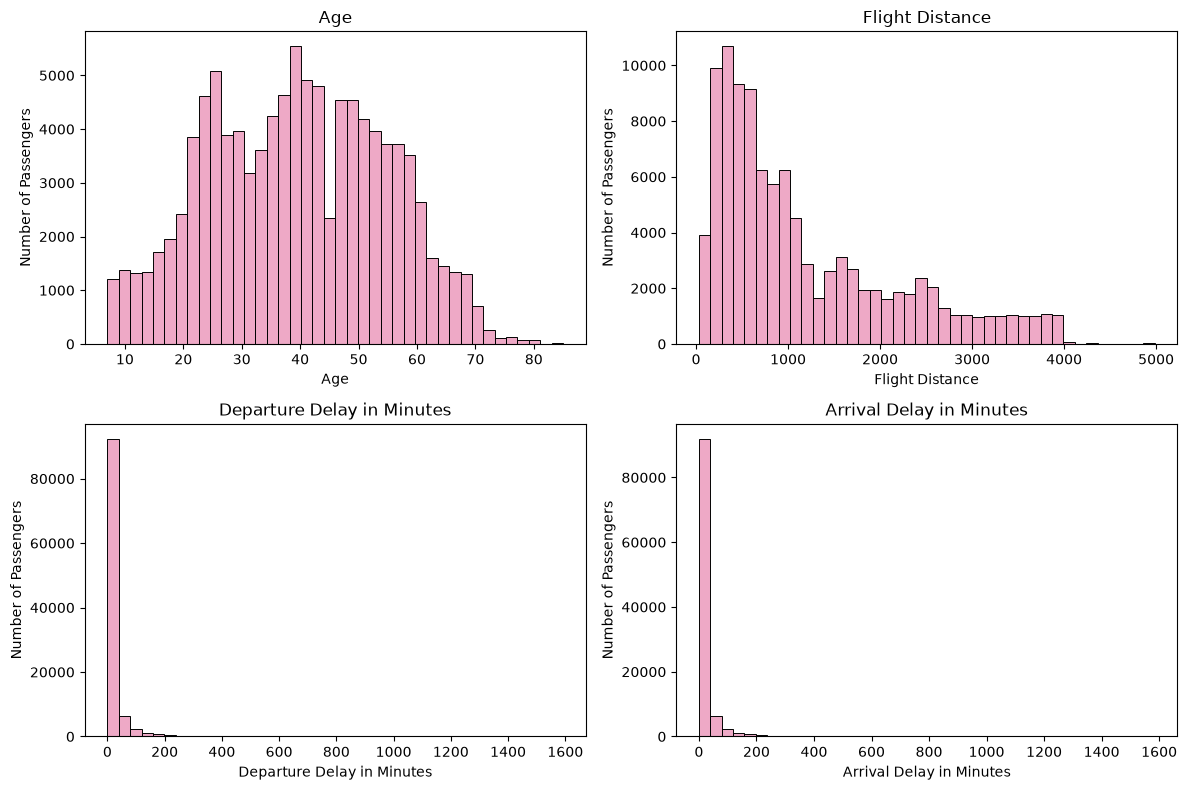

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

numerical_features = [
    "Age",
    "Flight Distance",
    "Departure Delay in Minutes",
    "Arrival Delay in Minutes"
]

fig, axes = plt.subplots(2, 2, figsize=(12, 8))

for ax, feature in zip(axes.flat, numerical_features):
    sns.histplot(
        data=train_df,
        x=feature,
        bins=40,
        color="#E98DB3",
        ax=ax
    )
    ax.set_title(feature)
    ax.set_ylabel("Number of Passengers")

plt.tight_layout()
plt.show()

In [11]:
# Explore categorical features

categorical_features = [
    "Gender",
    "Customer Type",
    "Type of Travel",
    "Class"
]

for feature in categorical_features:
    print(f"\n--- {feature} ---")
    print(train_df[feature].value_counts())


--- Gender ---
Gender
Female    52727
Male      51177
Name: count, dtype: int64

--- Customer Type ---
Customer Type
Loyal Customer       84923
disloyal Customer    18981
Name: count, dtype: int64

--- Type of Travel ---
Type of Travel
Business travel    71655
Personal Travel    32249
Name: count, dtype: int64

--- Class ---
Class
Business    49665
Eco         46745
Eco Plus     7494
Name: count, dtype: int64


In [12]:

# Satisfaction percentage for each category

for feature in categorical_features:
    print(f"\n--- Satisfaction by {feature} ---")

    satisfaction_rate = pd.crosstab(
        train_df[feature],
        train_df["satisfaction"],
        normalize="index"
    ) * 100

    print(satisfaction_rate.round(2))



--- Satisfaction by Gender ---
satisfaction  neutral or dissatisfied  satisfied
Gender                                          
Female                          57.26      42.74
Male                            56.05      43.95

--- Satisfaction by Customer Type ---
satisfaction       neutral or dissatisfied  satisfied
Customer Type                                        
Loyal Customer                       52.27      47.73
disloyal Customer                    76.33      23.67

--- Satisfaction by Type of Travel ---
satisfaction     neutral or dissatisfied  satisfied
Type of Travel                                     
Business travel                    41.74      58.26
Personal Travel                    89.83      10.17

--- Satisfaction by Class ---
satisfaction  neutral or dissatisfied  satisfied
Class                                           
Business                        30.57      69.43
Eco                             81.39      18.61
Eco Plus                        75.39     

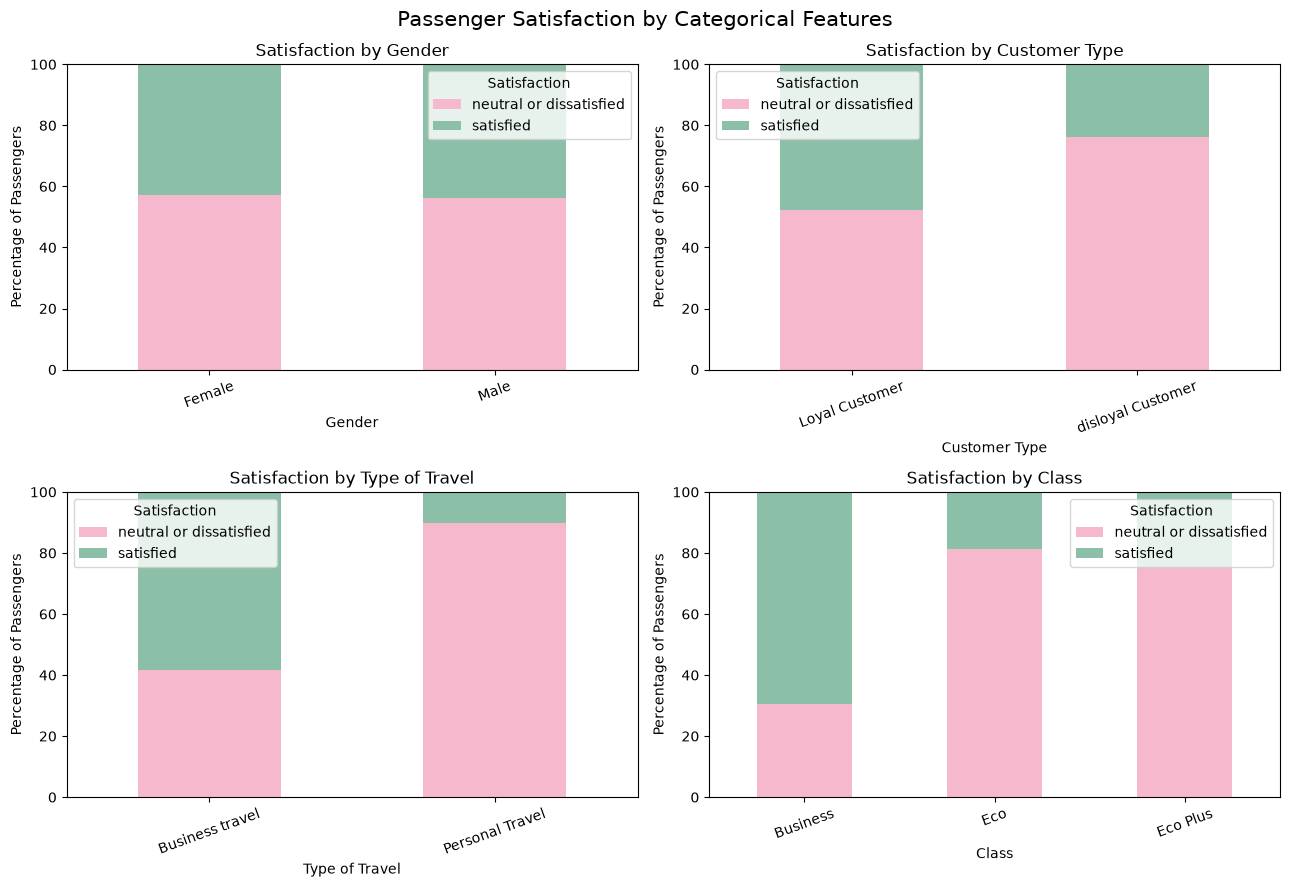

In [13]:

import matplotlib.pyplot as plt
import pandas as pd

fig, axes = plt.subplots(2, 2, figsize=(13, 9))

for ax, feature in zip(axes.flat, categorical_features):

    satisfaction_rates = pd.crosstab(
        train_df[feature],
        train_df["satisfaction"],
        normalize="index"
    ) * 100

    satisfaction_rates.plot(
        kind="bar",
        stacked=True,
        ax=ax,
        color=["#F5B8CC", "#8CBFA7"]
    )

    ax.set_title(f"Satisfaction by {feature}")
    ax.set_xlabel(feature)
    ax.set_ylabel("Percentage of Passengers")
    ax.set_ylim(0, 100)
    ax.tick_params(axis="x", rotation=20)
    ax.legend(title="Satisfaction")

plt.suptitle(
    "Passenger Satisfaction by Categorical Features",
    fontsize=15
)

plt.tight_layout()
plt.show()


In [14]:

# Step 1.13 — Service Ratings Analysis

service_features = [
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Inflight service",
    "Cleanliness"
]

# Calculate the average rating for each service
average_ratings = train_df[service_features].mean()

# Sort from highest to lowest
average_ratings = average_ratings.sort_values(
    ascending=False
)

print(average_ratings.round(2))


Inflight service                     3.64
Baggage handling                     3.63
Seat comfort                         3.44
On-board service                     3.38
Inflight entertainment               3.36
Leg room service                     3.35
Checkin service                      3.30
Cleanliness                          3.29
Online boarding                      3.25
Food and drink                       3.20
Departure/Arrival time convenient    3.06
Gate location                        2.98
Ease of Online booking               2.76
Inflight wifi service                2.73
dtype: float64


In [15]:

# Compare average service ratings by satisfaction

service_by_satisfaction = train_df.groupby(
    "satisfaction"
)[service_features].mean()

# Display the results
print(service_by_satisfaction.T.round(2))


satisfaction                       neutral or dissatisfied  satisfied
Inflight wifi service                                 2.40       3.16
Departure/Arrival time convenient                     3.13       2.97
Ease of Online booking                                2.55       3.03
Gate location                                         2.98       2.98
Food and drink                                        2.96       3.52
Online boarding                                       2.66       4.03
Seat comfort                                          3.04       3.97
Inflight entertainment                                2.89       3.96
On-board service                                      3.02       3.86
Leg room service                                      2.99       3.82
Baggage handling                                      3.38       3.97
Checkin service                                       3.04       3.65
Inflight service                                      3.39       3.97
Cleanliness         

In [16]:

# Calculate the difference between satisfaction groups

service_comparison = service_by_satisfaction.T.copy()

service_comparison["Difference"] = (
    service_comparison["satisfied"]
    - service_comparison["neutral or dissatisfied"]
)

# Sort by difference, highest first
service_comparison = service_comparison.sort_values(
    by="Difference",
    ascending=False
)

# Display results
print(service_comparison.round(2))


satisfaction                       neutral or dissatisfied  satisfied  \
Online boarding                                       2.66       4.03   
Inflight entertainment                                2.89       3.96   
Seat comfort                                          3.04       3.97   
On-board service                                      3.02       3.86   
Leg room service                                      2.99       3.82   
Cleanliness                                           2.94       3.74   
Inflight wifi service                                 2.40       3.16   
Checkin service                                       3.04       3.65   
Baggage handling                                      3.38       3.97   
Inflight service                                      3.39       3.97   
Food and drink                                        2.96       3.52   
Ease of Online booking                                2.55       3.03   
Gate location                                      

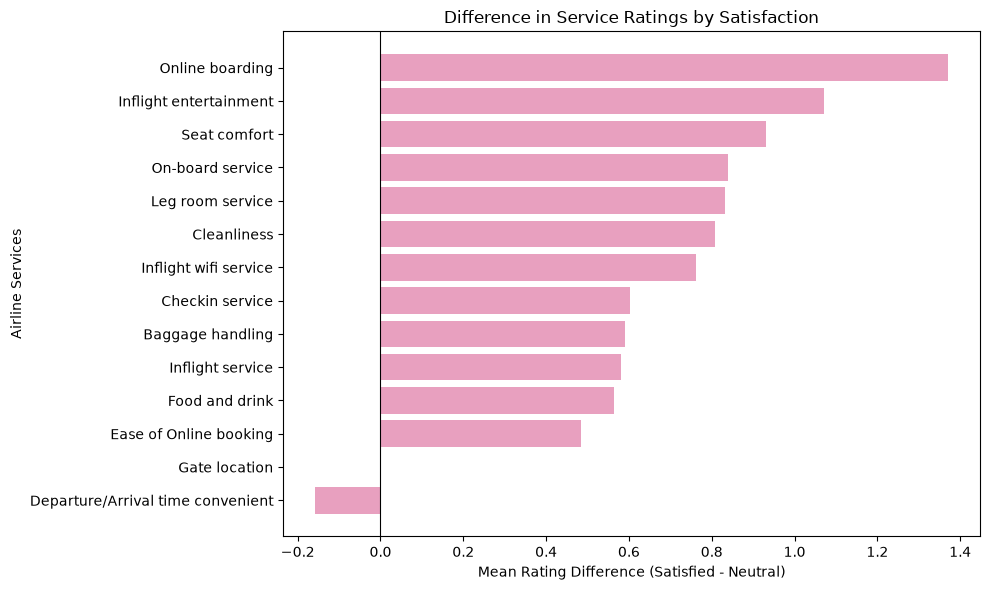

In [17]:

import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    service_comparison.index,
    service_comparison["Difference"],
    color="#E8A0BF"
)

plt.axvline(0, color="black", linewidth=0.8)

plt.title("Difference in Service Ratings by Satisfaction")
plt.xlabel("Mean Rating Difference (Satisfied - Neutral)")
plt.ylabel("Airline Services")

plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()


In [18]:

# Count zero ratings for each service

zero_counts = (train_df[service_features] == 0).sum()

zero_percentages = (
    zero_counts / len(train_df) * 100
)

zero_analysis = pd.DataFrame({
    "Zero Count": zero_counts,
    "Zero Percentage": zero_percentages
})

zero_analysis = zero_analysis.sort_values(
    by="Zero Count",
    ascending=False
)

print(zero_analysis.round(2))


                                   Zero Count  Zero Percentage
Departure/Arrival time convenient        5300             5.10
Ease of Online booking                   4487             4.32
Inflight wifi service                    3103             2.99
Online boarding                          2428             2.34
Leg room service                          472             0.45
Food and drink                            107             0.10
Inflight entertainment                     14             0.01
Cleanliness                                12             0.01
On-board service                            3             0.00
Inflight service                            3             0.00
Gate location                               1             0.00
Seat comfort                                1             0.00
Checkin service                             1             0.00
Baggage handling                            0             0.00


In [19]:

# Compare average ratings with and without zeros

raw_averages = train_df[service_features].mean()

nonzero_averages = (
    train_df[service_features]
    .replace(0, float("nan"))
    .mean()
)

average_comparison = pd.DataFrame({
    "Raw Average": raw_averages,
    "Average Without Zeros": nonzero_averages
})

average_comparison["Difference"] = (
    average_comparison["Average Without Zeros"]
    - average_comparison["Raw Average"]
)

print(
    average_comparison
    .sort_values("Difference", ascending=False)
    .round(2)
)


                                   Raw Average  Average Without Zeros  \
Departure/Arrival time convenient         3.06                   3.22   
Ease of Online booking                    2.76                   2.88   
Inflight wifi service                     2.73                   2.81   
Online boarding                           3.25                   3.33   
Leg room service                          3.35                   3.37   
Food and drink                            3.20                   3.21   
Inflight entertainment                    3.36                   3.36   
Cleanliness                               3.29                   3.29   
Inflight service                          3.64                   3.64   
On-board service                          3.38                   3.38   
Seat comfort                              3.44                   3.44   
Checkin service                           3.30                   3.30   
Gate location                             2.98     

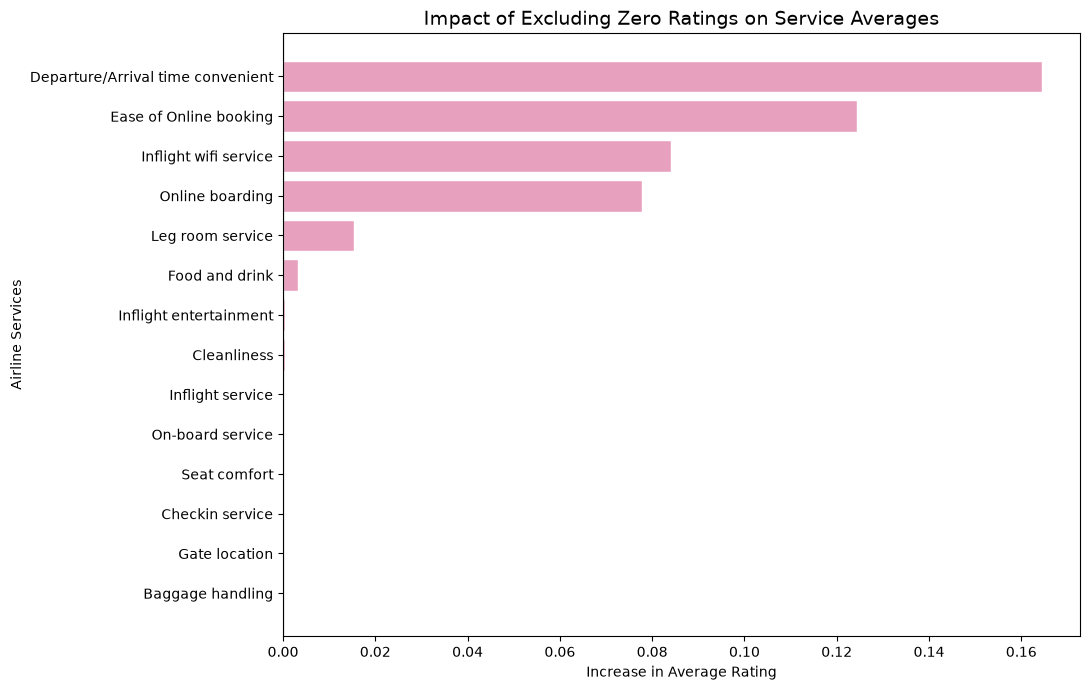

In [20]:

# Step 13.4 — Visualisation of the Impact of Zero Ratings

import matplotlib.pyplot as plt

# Sort services by the impact of excluding zeros
plot_data = average_comparison.sort_values(
    by="Difference",
    ascending=True
)

plt.figure(figsize=(11, 7))

# Create horizontal bar chart
plt.barh(
    plot_data.index,
    plot_data["Difference"],
    color="#E8A0BF",
    edgecolor="white"
)

plt.title(
    "Impact of Excluding Zero Ratings on Service Averages",
    fontsize=14
)

plt.xlabel("Increase in Average Rating")
plt.ylabel("Airline Services")

plt.axvline(0, color="black", linewidth=0.8)

plt.tight_layout()
plt.show()
